In [1]:
# ==========================================
# CELL 1: Imports & Data Loading
# ==========================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from stockFunctions import graph, rmsemape

dataset = pd.read_csv("v1Capstone-FP&A_Time_Series_Capstone_Dataset.csv")
dataset


,Client Name,Month,Scenario,Revenue GL Account,Revenue,Cost GL Account,Cost,CCI,CCI %
0,Client A,2025-01-01,Actual,400000 - Revenue,965265.51,500000 - Cost,667654.97,297610.54,30.83
1,Client A,2025-02-01,Actual,400000 - Revenue,994900.11,500000 - Cost,703916.22,290983.89,29.25
2,Client A,2025-03-01,Actual,400000 - Revenue,988177.46,500000 - Cost,681429.95,306747.51,31.04
3,Client A,2025-04-01,Actual,400000 - Revenue,1049206.88,500000 - Cost,731790.39,317416.49,30.25
4,Client A,2025-05-01,Actual,400000 - Revenue,1069524.81,500000 - Cost,741368.55,328156.26,30.68
...,...,...,...,...,...,...,...,...,...
115,Client E,2026-08-01,Budget,400000 - Revenue,510111.92,500000 - Cost,366524.48,143587.44,28.15
116,Client E,2026-09-01,Budget,400000 - Revenue,505305.10,500000 - Cost,365202.83,140102.27,27.73
117,Client E,2026-10-01,Budget,400000 - Revenue,525368.68,500000 - Cost,377466.88,147901.80,28.15
118,Client E,2026-11-01,Budget,400000 - Revenue,540729.46,500000 - Cost,388051.30,152678.16,28.24


In [2]:
# ==========================================
# CELL 2: Filter, Sort, Index & Scale Data
# ==========================================
# Select Client A, sort by Month, and set Month as index upfront
client_data = dataset[dataset['Client Name'] == 'Client A'].copy()
client_data['Month'] = pd.to_datetime(client_data['Month'])
client_data = client_data.sort_values('Month')
client_data = client_data.set_index('Month')

# Select Revenue & Cost
data1 = client_data[['Revenue']]
cost_data = client_data[['Cost']]

# Split into training (first 19 months) and testing (last 5 months)
train = data1[:-5]
test = data1[-5:]

train_cost = cost_data[:-5]
test_cost = cost_data[-5:]

# Apply MinMaxScaler for Revenue
Ms = MinMaxScaler()
train_scaled = Ms.fit_transform(train)
test_scaled = Ms.transform(test)

# Apply separate MinMaxScaler for Cost
Ms_cost = MinMaxScaler()
train_cost_scaled = Ms_cost.fit_transform(train_cost)
test_cost_scaled = Ms_cost.transform(test_cost)

print("Original data:", data1.shape)
print("Training data:", train_scaled.shape)
print("Testing data:", test_scaled.shape)


Original data: (24, 1)
Training data: (19, 1)
Testing data: (5, 1)


In [3]:
# ==========================================
# CELL 3: ARIMA Parameter Tuning (Revenue)
# ==========================================
orders = [(1, 1, 1), (1, 1, 2), (2, 1, 1), (2, 2, 2)]
results = []

Y_test_original = Ms.inverse_transform(test_scaled)

for i in orders:
  model = ARIMA(train_scaled, order=i)
  model_fit = model.fit()

  # Forecast next 5 months (Test set)
  y_pred = model_fit.forecast(steps=len(test_scaled))
  y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))

  # Calculate accuracy
  rmse, mape = rmsemape(Y_test_original, y_pred_original)
  results.append([i, rmse, mape])

  print("ARIMA Order:", i)
  print("RMSE:", rmse)
  print("MAPE:", mape)
  print("***************")

# Create comparison table
df = pd.DataFrame(results, columns=['ARIMA Order', 'RMSE', 'MAPE'])
df = df.sort_values(by='RMSE').reset_index(drop=True)

df.style.format({'RMSE': '{:.2f}', 'MAPE': '{:.2%}'}).highlight_min(
    subset=['RMSE', 'MAPE'], color='lightgreen'
)


RMSE-Testset: 106851.0161906335
MAPE-Testset: 0.06395212940136805
ARIMA Order: (1, 1, 1)
RMSE: 106851.0161906335
MAPE: 0.06395212940136805
***************


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible sta

RMSE-Testset: 62341.72262187982
MAPE-Testset: 0.03536146603265995
ARIMA Order: (1, 1, 2)
RMSE: 62341.72262187982
MAPE: 0.03536146603265995
***************
RMSE-Testset: 107379.46794497735
MAPE-Testset: 0.06437396407684756
ARIMA Order: (2, 1, 1)
RMSE: 107379.46794497735
MAPE: 0.06437396407684756
***************
RMSE-Testset: 51160.65773952331
MAPE-Testset: 0.029428209327142674
ARIMA Order: (2, 2, 2)
RMSE: 51160.65773952331
MAPE: 0.029428209327142674
***************


,ARIMA Order,RMSE,MAPE
0,"(2, 2, 2)",51160.66,2.94%
1,"(1, 1, 2)",62341.72,3.54%
2,"(1, 1, 1)",106851.02,6.40%
3,"(2, 1, 1)",107379.47,6.44%


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 51160.65773952331
MAPE-Testset: 0.029428209327142674
Revenue RMSE: 51160.65773952331
Revenue MAPE: 0.029428209327142674


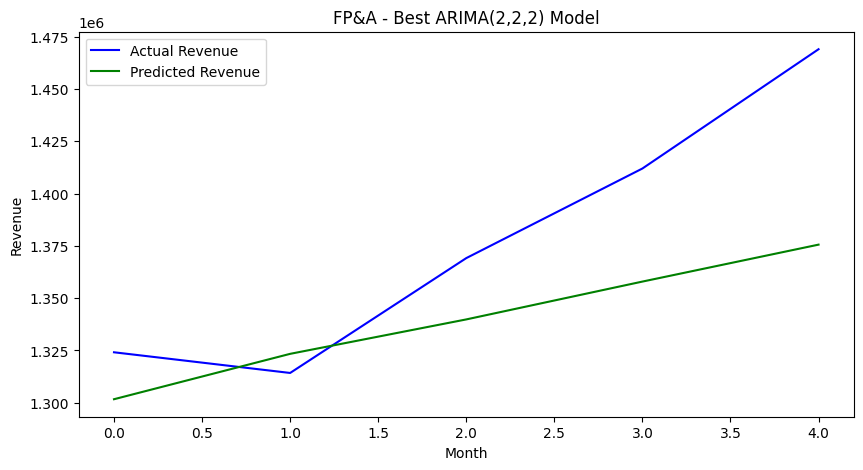

In [4]:
# ==========================================
# CELL 4: Evaluate Best Revenue Model & Plot
# ==========================================
model = ARIMA(train_scaled, order=(2, 2, 2))
model_fit = model.fit()

y_pred = model_fit.forecast(steps=len(test_scaled))
y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))
Y_test_original = Ms.inverse_transform(np.array(test_scaled).reshape(-1, 1))

rmse, mape = rmsemape(Y_test_original, y_pred_original)
print("Revenue RMSE:", rmse)
print("Revenue MAPE:", mape)

graph(
    Y_test_original,
    y_pred_original,
    "Actual Revenue",
    "Predicted Revenue",
    "FP&A - Best ARIMA(2,2,2) Model",
    "Month",
    "Revenue",
)


In [5]:
# ==========================================
# CELL 5: Evaluate Best Cost Model
# ==========================================
model_cost = ARIMA(train_cost_scaled, order=(2, 2, 2))
model_cost_fit = model_cost.fit()

y_pred_cost = model_cost_fit.forecast(steps=len(test_cost_scaled))
y_pred_cost_original = Ms_cost.inverse_transform(
    np.array(y_pred_cost).reshape(-1, 1)
)
Y_test_cost_original = Ms_cost.inverse_transform(test_cost_scaled)

rmse_cost, mape_cost = rmsemape(Y_test_cost_original, y_pred_cost_original)
print("Cost RMSE:", rmse_cost)
print("Cost MAPE:", mape_cost)


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 32733.914795907378
MAPE-Testset: 0.026147873338104227
Cost RMSE: 32733.914795907378
Cost MAPE: 0.026147873338104227


In [6]:
# ==========================================
# CELL 6: Test Set Comparison (CCI & CCI%)
# ==========================================
actual_cci = Y_test_original.flatten() - Y_test_cost_original.flatten()
actual_cci_percent = (actual_cci / Y_test_original.flatten()) * 100

predicted_cci = y_pred_original.flatten() - y_pred_cost_original.flatten()
predicted_cci_percent = (predicted_cci / y_pred_original.flatten()) * 100

cci_df = pd.DataFrame({
    'Month': client_data.index[-5:],
    'Actual Revenue': Y_test_original.flatten(),
    'Predicted Revenue': y_pred_original.flatten(),
    'Actual Cost': Y_test_cost_original.flatten(),
    'Predicted Cost': y_pred_cost_original.flatten(),
    'Actual CCI': actual_cci,
    'Predicted CCI': predicted_cci,
    'Actual CCI%': actual_cci_percent,
    'Predicted CCI%': predicted_cci_percent,
})

print(cci_df.round(2).to_string(index=False))


     Month  Actual Revenue  Predicted Revenue  Actual Cost  Predicted Cost  Actual CCI  Predicted CCI  Actual CCI%  Predicted CCI%
2026-08-01      1324125.41         1301694.17    922625.10       913794.82   401500.31      387899.35        30.32           29.80
2026-09-01      1314245.40         1323380.37    915323.65       931011.00   398921.75      392369.38        30.35           29.65
2026-10-01      1369134.47         1339832.84    952313.37       942199.91   416821.10      397632.93        30.44           29.68
2026-11-01      1411955.78         1357915.22    988154.34       955450.25   423801.44      402464.98        30.02           29.64
2026-12-01      1468961.84         1375572.93   1030310.62       968168.53   438651.22      407404.40        29.86           29.62


In [7]:
# ==========================================
# CELL 7: Retrain on Full Data & Forecast Next 4 Months
# ==========================================
# Fit scalers on all 24 months
full_rev_scaled = Ms.fit_transform(data1)
full_cost_scaled = Ms_cost.fit_transform(cost_data)

# Retrain final models on full 24 months
final_model_rev = ARIMA(full_rev_scaled, order=(2, 2, 2)).fit()
final_model_cost = ARIMA(full_cost_scaled, order=(2, 2, 2)).fit()

# Forecast next 4 future months (Jan - Apr 2027)
forecast_revenue = final_model_rev.forecast(steps=4)
revenue_original = Ms.inverse_transform(
    np.array(forecast_revenue).reshape(-1, 1)
).flatten()

forecast_cost = final_model_cost.forecast(steps=4)
cost_original = Ms_cost.inverse_transform(
    np.array(forecast_cost).reshape(-1, 1)
).flatten()

# Generate next 4 months dates
last_date = client_data.index.max()
future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1), periods=4, freq='MS'
)

# Calculate Future CCI and CCI%
forecast_cci = revenue_original - cost_original
forecast_cci_percent = (forecast_cci / revenue_original) * 100

# Create final FP&A forecast DataFrame
forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Predicted Revenue': revenue_original,
    'Predicted Cost': cost_original,
    'Predicted CCI': forecast_cci,
    'Predicted CCI%': forecast_cci_percent,
})

forecast_df = forecast_df.round(2)
print(forecast_df.to_string(index=False))


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


     Month  Predicted Revenue  Predicted Cost  Predicted CCI  Predicted CCI%
2027-01-01         1469154.82      1032756.51      436398.31           29.70
2027-02-01         1487070.85      1056381.61      430689.23           28.96
2027-03-01         1508390.56      1064249.73      444140.82           29.44
2027-04-01         1529430.42      1086271.23      443159.18           28.98


In [41]:

import numpy as np
import pandas as pd

# Forecast next four months - Revenue
forecast_revenue = model_fit.forecast(steps=4)

# Convert scaled Revenue back to original values
revenue_original = Ms.inverse_transform(
    np.array(forecast_revenue).reshape(-1, 1)
).flatten()


# Forecast next four months - Cost
forecast_cost = model_cost_fit.forecast(steps=4)

# Convert scaled Cost back to original values
cost_original = Ms_cost.inverse_transform(
    np.array(forecast_cost).reshape(-1, 1)
).flatten()


# Get the last actual month
last_date = client_data.index.max()

# Generate next four months
future_dates = pd.date_range(
    start=last_date + pd.DateOffset(months=1),
    periods=4,
    freq='MS'
)


# Calculate CCI and CCI%
forecast_cci = revenue_original - cost_original

forecast_cci_percent = (
    forecast_cci / revenue_original
) * 100


# Create final FP&A forecast DataFrame
forecast_df = pd.DataFrame({
    'Month': future_dates,
    'Predicted Revenue': revenue_original,
    'Predicted Cost': cost_original,
    'Predicted CCI': forecast_cci,
    'Predicted CCI%': forecast_cci_percent
})

# Round values
forecast_df = forecast_df.round(2)

# Display output
print(forecast_df.to_string(index=False))


     Month  Predicted Revenue  Predicted Cost  Predicted CCI  Predicted CCI%
2027-01-01       1,301,694.17      913,794.82     387,899.35           29.80
2027-02-01       1,323,380.37      931,011.00     392,369.38           29.65
2027-03-01       1,339,832.84      942,199.91     397,632.93           29.68
2027-04-01       1,357,915.22      955,450.25     402,464.98           29.64


In [11]:
forecast_df.to_csv("Final Forecast.csv",index=False,float_format="%.2f")